---
#### Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

---
#### Load Data

In [2]:
data = pd.read_csv("Player-Season_Statlines_for_Modeling.csv")
data.head()

,Unnamed: 0,season_id,player_id,team_id,2P,2P%,2PA,3P,3P%,3PA,...,eFG%,vote_id,rank,first_place_votes,second_place_votes,third_place_votes,points_won,age,points_max,points_share
0,0,1,1,10,3.0,0.504,6.0,2.8,0.420,6.6,...,0.569,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,1,2,24,2.9,0.576,5.1,0.0,0.375,0.1,...,0.575,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,1,3,11,0.3,1.000,0.3,0.0,0.000,0.7,...,0.333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,1,4,12,5.2,0.538,9.7,1.5,0.396,3.7,...,0.554,839.0,Received Votes,0.0,NaN,NaN,28.0,22.0,500.0,0.056
4,4,1,5,19,4.5,0.469,9.5,2.9,0.384,7.5,...,0.516,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


---
#### Data Types of each column

In [3]:
file_info = pd.DataFrame()
file_info["Data Type"] = data.dtypes
file_info["Missing No."] = data.isna().sum()
pd.set_option('display.max_rows', None)

file_info

,Data Type,Missing No.
Unnamed: 0,int64,0
season_id,int64,0
player_id,int64,0
team_id,int64,0
2P,float64,0
2P%,float64,111
2PA,float64,0
3P,float64,0
3P%,float64,1500
3PA,float64,0


In [4]:
# Revert back "max rows" options
pd.reset_option('display.max_rows', None)

---
#### Address Missingness

In [5]:
# Voting columns fill with "0"
vote_cols_to_fill = [
    "first_place_votes", "second_place_votes", "third_place_votes",
    "points_share", "points_won"
]

data[vote_cols_to_fill] = data[vote_cols_to_fill].fillna(0)

In [6]:
# Remove "age" and Excel-generated index column
data = data.drop(columns=["age", "Unnamed: 0"])

In [7]:
# Fill with 0 for specific stats columns
zero_fill_cols = ['3P%', '3PAr']
data[zero_fill_cols] = data[zero_fill_cols].fillna(0)

In [8]:
# Fill with median where 0 would be misleading
median_fill_cols = ['FTr', 'FT%']
for col in median_fill_cols:
    median_val = data[col].median()
    data[col] = data[col].fillna(median_val)

In [9]:
# Fill remaining missing numerical features with median
advanced_stats_with_nans = [
    '2P%', 'AST%', 'BLK%', 'BPM', 'DBPM', 'DRB%', 'DWS', 'FG%', 'OBPM', 'ORB%',
    'OWS', 'PER', 'STL%', 'TOV%', 'TRB%', 'TS%', 'Trp-Dbl', 'USG%', 'VORP', 'WS', 'WS/48', 'eFG%'
]

for col in advanced_stats_with_nans:
    data[col] = data[col].fillna(data[col].median())

In [10]:
# Confirm changes
print("Remaining missing values:")
print(data.isna().sum()[data.isna().sum() > 0])

Remaining missing values:
vote_id       11772
rank          11772
points_max    11772
dtype: int64


In [11]:
# Drop non-feature columns
data = data.drop(columns=["vote_id", "rank", "points_max"])

---
#### Select target and features

In [12]:
# Target
y = data["points_share"]

In [13]:
# Columns to exclude for model:
excluded_cols = ["player_id", "season_id", "team_id", "vote_id", "rank",
                 "first_place_votes", "second_place_votes", "third_place_votes",
                 "points_won", "points_max", "points", "share", "points_share"]

In [14]:
# Select remaining columns not in 'excluded_cols'
X = data.drop(columns=[col for col in excluded_cols if col in data.columns])

---
#### Run Random Forest to select features

In [15]:
# Import libraries
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

In [16]:
# For newer versions of Python/Jupyter, change default so that method config attributes always show
from sklearn import set_config
set_config(print_changed_only=False, display='diagram')

In [17]:
# Split data for training and testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [18]:
rf = RandomForestRegressor(n_estimators=100, random_state=1)
rf.fit(X_train, y_train)

RandomForestRegressor(bootstrap=True, ccp_alpha=0.0, criterion='squared_error',
                      max_depth=None, max_features=1.0, max_leaf_nodes=None,
                      max_samples=None, min_impurity_decrease=0.0,
                      min_samples_leaf=1, min_samples_split=2,
                      min_weight_fraction_leaf=0.0, monotonic_cst=None,
                      n_estimators=100, n_jobs=None, oob_score=False,
                      random_state=1, verbose=0, warm_start=False)

In [19]:
y_pred = rf.predict(X_test)
print("R_squared: ", round(r2_score(y_test, y_pred), 3))
print("MAE: ", round(mean_absolute_error(y_test, y_pred), 3))
print("RMSE: ", round(root_mean_squared_error(y_test, y_pred), 3))

R_squared:  0.722
MAE:  0.01
RMSE:  0.052


---
#### Run random forest 10 times with different random states

In [20]:
rf_results = []
important_features = pd.DataFrame(index=X.columns)

num_runs = 10

for i in range(num_runs):
    seed = np.random.randint(1, 100)
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)
    
    rf = RandomForestRegressor(n_estimators=100, random_state=1)
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)
    
    rf_results.append({
        "run_num" : i + 1,
        "random_state" : seed,
        "R_squared" : round(r2_score(y_test, y_pred), 3),
        "MAE" : round(mean_absolute_error(y_test, y_pred), 3), 
        "RMSE" : round(root_mean_squared_error(y_test, y_pred), 3)
    })
    
    important_features[f'run_{i+1}'] = rf.feature_importances_

rf_results_df = pd.DataFrame(rf_results)
rf_results_df

,run_num,random_state,R_squared,MAE,RMSE
0,1,89,0.809,0.011,0.054
1,2,19,0.834,0.009,0.044
2,3,16,0.767,0.010,0.051
3,4,35,0.776,0.010,0.050
4,5,74,0.821,0.009,0.044
5,6,43,0.726,0.010,0.052
6,7,50,0.778,0.011,0.054
7,8,43,0.726,0.010,0.052
8,9,8,0.801,0.009,0.050
9,10,17,0.798,0.011,0.053


In [21]:
# Summarize results
rf_results_df[["R_squared", "MAE", "RMSE"]].describe()

,R_squared,MAE,RMSE
count,10.000000,10.000000,10.000000
mean,0.783600,0.010000,0.050400
std,0.036658,0.000816,0.003658
min,0.726000,0.009000,0.044000
25%,0.769250,0.009250,0.050000
50%,0.788000,0.010000,0.051500
75%,0.807000,0.010750,0.052750
max,0.834000,0.011000,0.054000


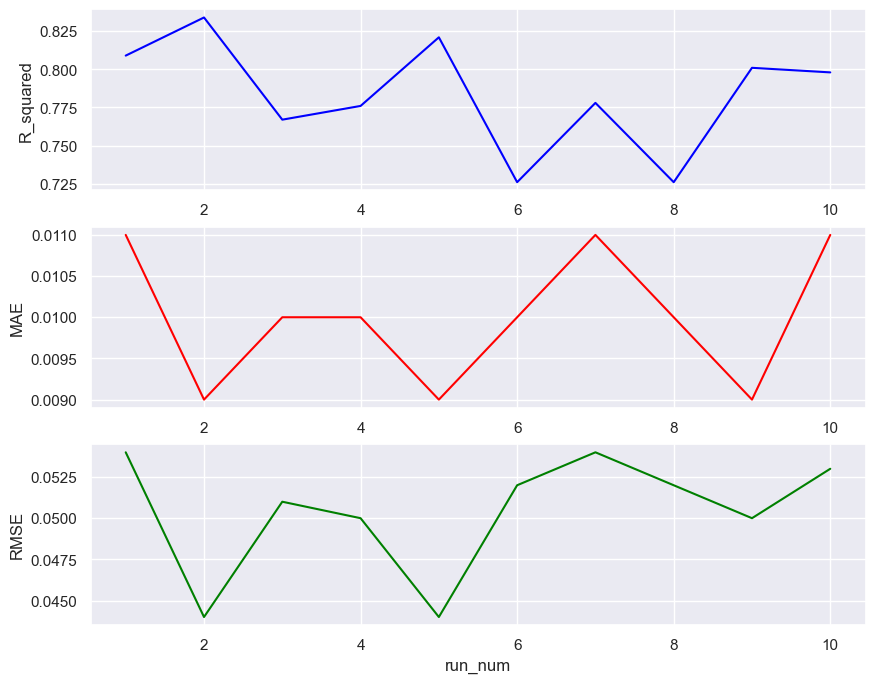

In [22]:
# Visualize results
fig, axs = plt.subplots(3, 1, figsize=(10, 8))

sns.lineplot(data=rf_results_df, x="run_num", y="R_squared", ax=axs[0], color="blue")
sns.lineplot(data=rf_results_df, x="run_num", y="MAE", ax=axs[1], color="red")
sns.lineplot(data=rf_results_df, x="run_num", y="RMSE", ax=axs[2], color="green")
plt.show()

---
#### Feature Selection from Random Forest Runs

In [29]:
important_features

,run_1,run_2,run_3,run_4,run_5,run_6,run_7,run_8,run_9,run_10
2P,0.016074,0.016550,0.023019,0.022083,0.017653,0.015996,0.019256,0.015996,0.011506,0.023197
2P%,0.005397,0.003764,0.003241,0.004813,0.005408,0.003553,0.003017,0.003553,0.005319,0.004534
2PA,0.007956,0.008356,0.009497,0.004700,0.008797,0.005119,0.010305,0.005119,0.006529,0.007027
3P,0.002036,0.002306,0.002419,0.002357,0.002903,0.001935,0.002204,0.001935,0.002662,0.002546
3P%,0.007599,0.005968,0.011634,0.006437,0.007065,0.004914,0.007013,0.004914,0.008216,0.006731
3PA,0.003863,0.003907,0.003803,0.002787,0.003829,0.003613,0.003452,0.003613,0.003696,0.002605
3PAr,0.002777,0.002682,0.003614,0.002364,0.004096,0.002848,0.003290,0.002848,0.002907,0.002568
AST,0.007732,0.006043,0.006422,0.007775,0.004633,0.007403,0.004069,0.007403,0.004835,0.006715
AST%,0.006221,0.005996,0.005931,0.004503,0.003600,0.004755,0.004270,0.004755,0.003975,0.009354
BLK,0.003172,0.002598,0.002763,0.002232,0.002762,0.003007,0.003185,0.003007,0.001894,0.003416


In [24]:
# Average importance for each feature
avg_importance = important_features.mean(axis=1).sort_values(ascending=False)

In [39]:
# Top N features
n_features = 10 
top_features = avg_importance.head(n_features)
top_features = pd.DataFrame(top_features).rename(columns={0 : "Average Importance"})
top_features

,Average Importance
VORP,0.618568
PER,0.076923
FG,0.020497
2P,0.018133
DWS,0.016834
USG%,0.015577
WS/48,0.014433
WS,0.013950
PTS,0.013849
FTA,0.012414


In [40]:
# Top features columns
top_features.index.to_list()

['VORP', 'PER', 'FG', '2P', 'DWS', 'USG%', 'WS/48', 'WS', 'PTS', 'FTA']

In [42]:
# Export only rows for modeling
data[['points_share', 'VORP', 'PER', 'FG', '2P', 'DWS', 'USG%', 'WS/48', 'WS', 'PTS', 'FTA']]\
.to_csv("data_for_modeling.csv", index=False)